# Лабораторная работа 5. Обработка текста

Датасет: `datasets/sms_spam.csv`.

In [1]:
import pandas as pd

df = pd.read_csv('sms_spam.csv')
print(df.head())
print(df["label"].value_counts())

  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4827
spam     747
Name: count, dtype: int64


# Задание 1
Разбейте предложения на слова. С помощью TF-IDF преобразуйте текст в вектор.

In [3]:
import re

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

df["tokens"] = df["text"].apply(tokenize)

print(df[["text", "tokens"]].head())

                                                text  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                              tokens  
0  [go, until, jurong, point, crazy, available, o...  
1                     [ok, lar, joking, wif, u, oni]  
2  [free, entry, in, 2, a, wkly, comp, to, win, f...  
3  [u, dun, say, so, early, hor, u, c, already, t...  
4  [nah, i, don, t, think, he, goes, to, usf, he,...  


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b"
)

X = vectorizer.fit_transform(df["text"])

print("Matrix size:", X.shape)
print("Words count in dictionary:", len(vectorizer.vocabulary_))
# Каждая строка — SMS, каждый столбец — слово из словаря, каждое значение — вес TF-IDF.

Matrix size: (5574, 8753)
Words count in dictionary: 8753


In [5]:
for i in range(5):
    print(f"\nSMS {i}: {df['text'].iloc[i]}")

    row = X[i]
    words = vectorizer.get_feature_names_out()[row.indices]
    weights = row.data

    print(dict(zip(words, weights)))


SMS 0: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
{'go': np.float64(0.14322796823909992), 'until': np.float64(0.22278387630668048), 'jurong': np.float64(0.31619888739597046), 'point': np.float64(0.24731928553477678), 'crazy': np.float64(0.24487713705141087), 'available': np.float64(0.23650965671043886), 'only': np.float64(0.15112660578918274), 'in': np.float64(0.10363494393760958), 'bugis': np.float64(0.26712806893977786), 'n': np.float64(0.16898643202739272), 'great': np.float64(0.1746741244844783), 'world': np.float64(0.21388807103511331), 'la': np.float64(0.26712806893977786), 'e': np.float64(0.1826540413199169), 'buffet': np.float64(0.3018465930576863), 'cine': np.float64(0.26712806893977786), 'there': np.float64(0.1506292142811798), 'got': np.float64(0.1482419876291885), 'amore': np.float64(0.31619888739597046), 'wat': np.float64(0.17667826988574492)}

SMS 1: Ok lar... Joking wif u oni...
{'ok': np.float64(0.266

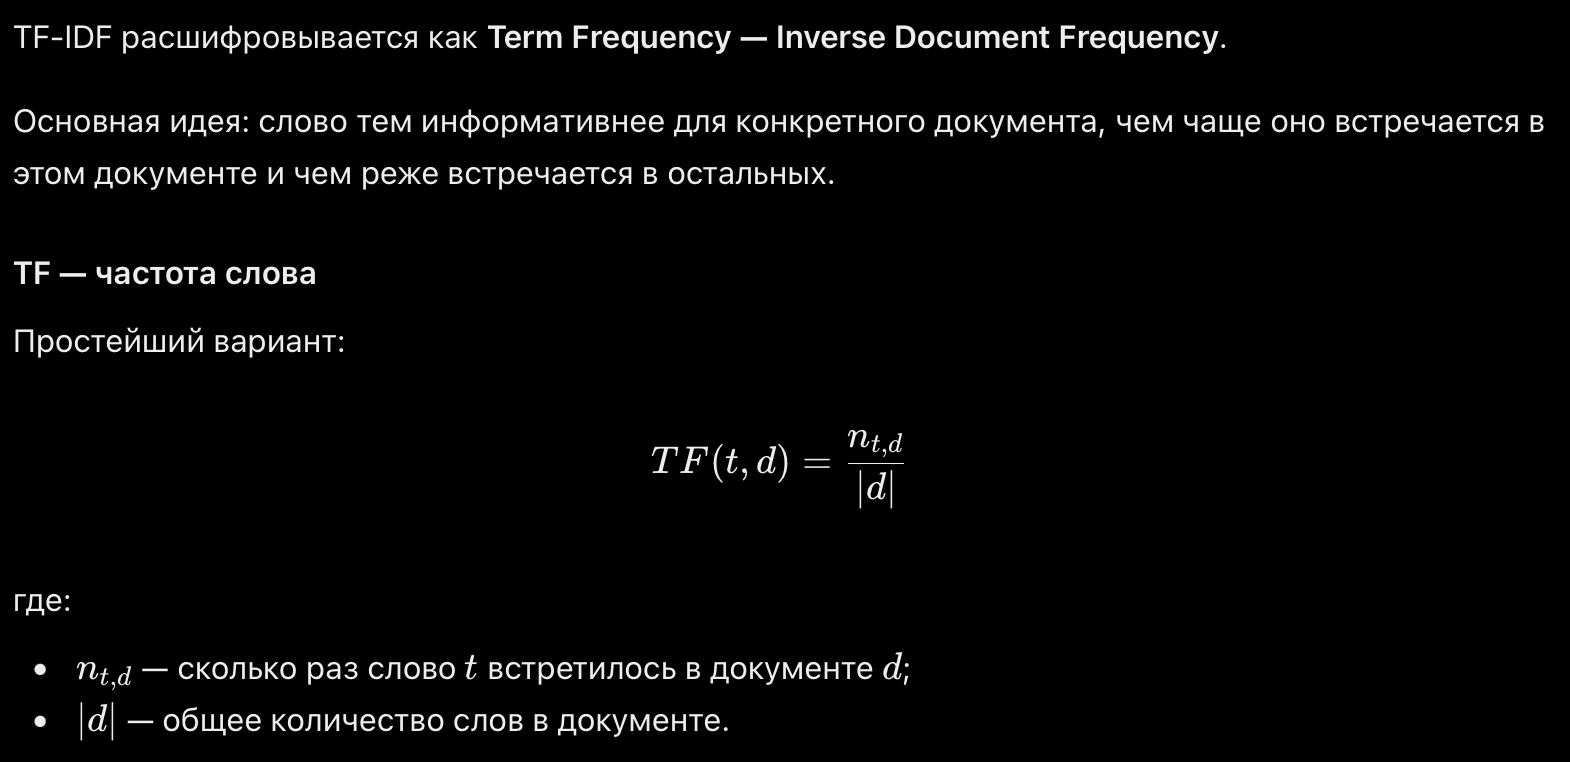 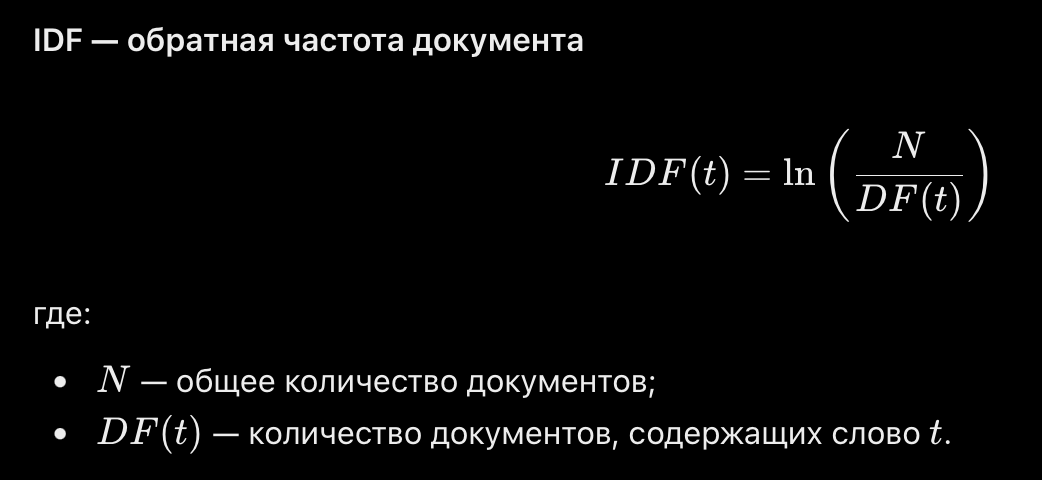 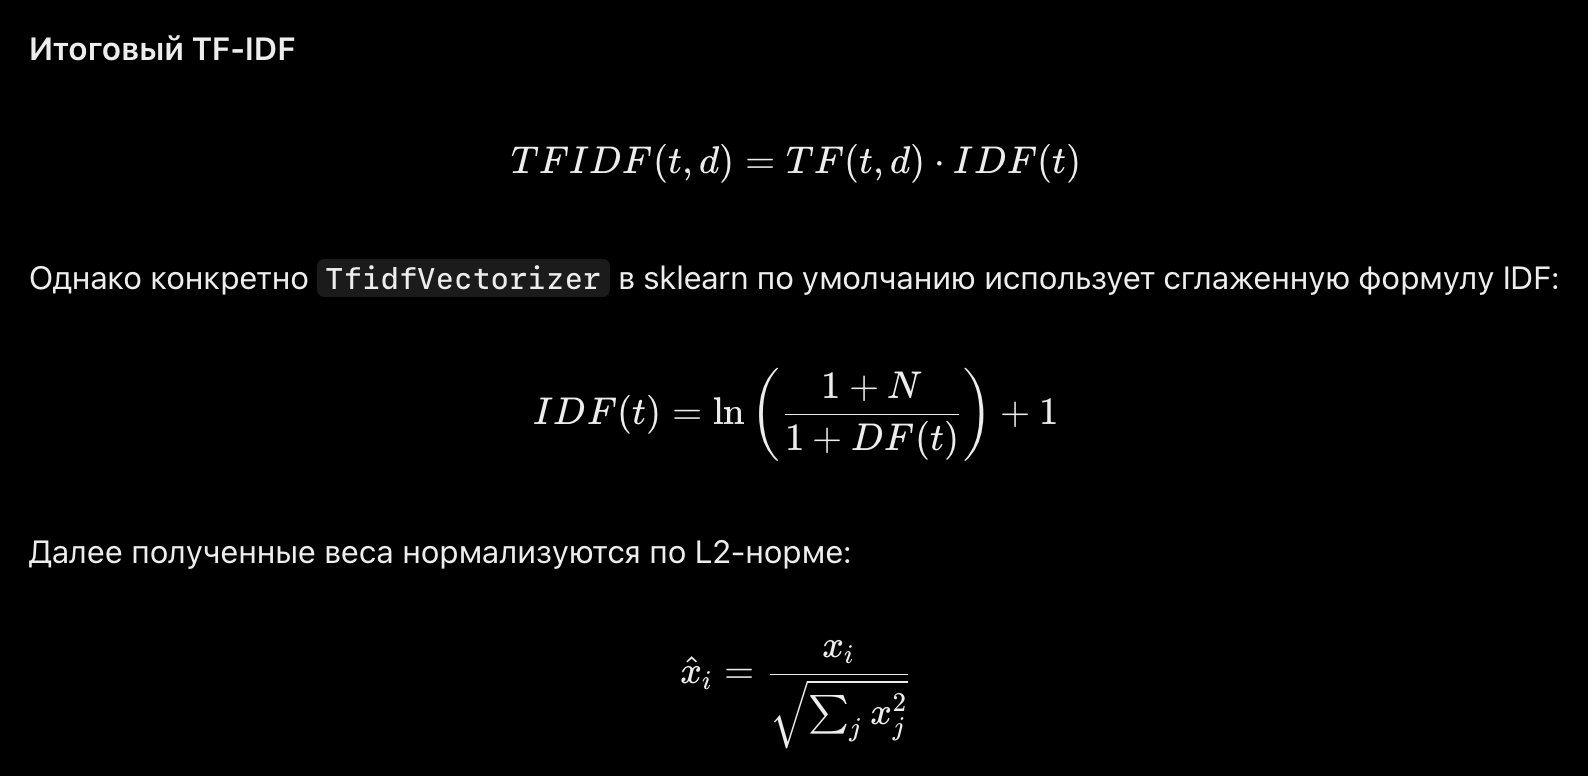

# Задние 2.

Выберите 2 метода из 3 (XGBoost, LightGBM, CatBoost). Обучите модели, оцените гиперпараметры. Для каждой модели посчитайте Accuracy, Precision, Recall, F1-score. Постройте confusion matrix и roc-кривую.

In [6]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"],
    df["label"].map({"ham": 0, "spam": 1}),
    test_size=0.2,
    random_state=666,
    stratify=df["label"]
)

# to TF-IDF
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (4459, 7810)
Test: (1115, 7810)


In [14]:
# xgboost
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

xgb_params = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    XGBClassifier(objective="binary:logistic",tree_method="hist",random_state=666,n_jobs=1),
    xgb_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print("XGBoost")
print("Best params:", xgb_grid.best_params_)
print("Best CV F1:", xgb_grid.best_score_)

XGBoost
Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Best CV F1: 0.916690736423285


In [15]:
# lightGBM
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

def lgbm_f1(model, X, y):
    y_proba = model.booster_.predict(X)
    y_pred = (y_proba >= 0.5).astype(int)
    return f1_score(y, y_pred)

lgbm_params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "num_leaves": [7, 15],
    "min_child_samples": [10, 20]
}
# min_child_samples - Минимальное количество объектов в листе. 

lgbm_grid = GridSearchCV(
    LGBMClassifier(objective="binary", random_state=666, verbosity=-1,n_jobs=1),
    lgbm_params,
    cv=5,
    scoring=lgbm_f1,
    n_jobs=-1
)

lgbm_grid.fit(X_train, y_train)

print("Best params:", lgbm_grid.best_params_)
print("Best CV F1:", lgbm_grid.best_score_)

Best params: {'learning_rate': 0.1, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 15}
Best CV F1: 0.9325925042107428


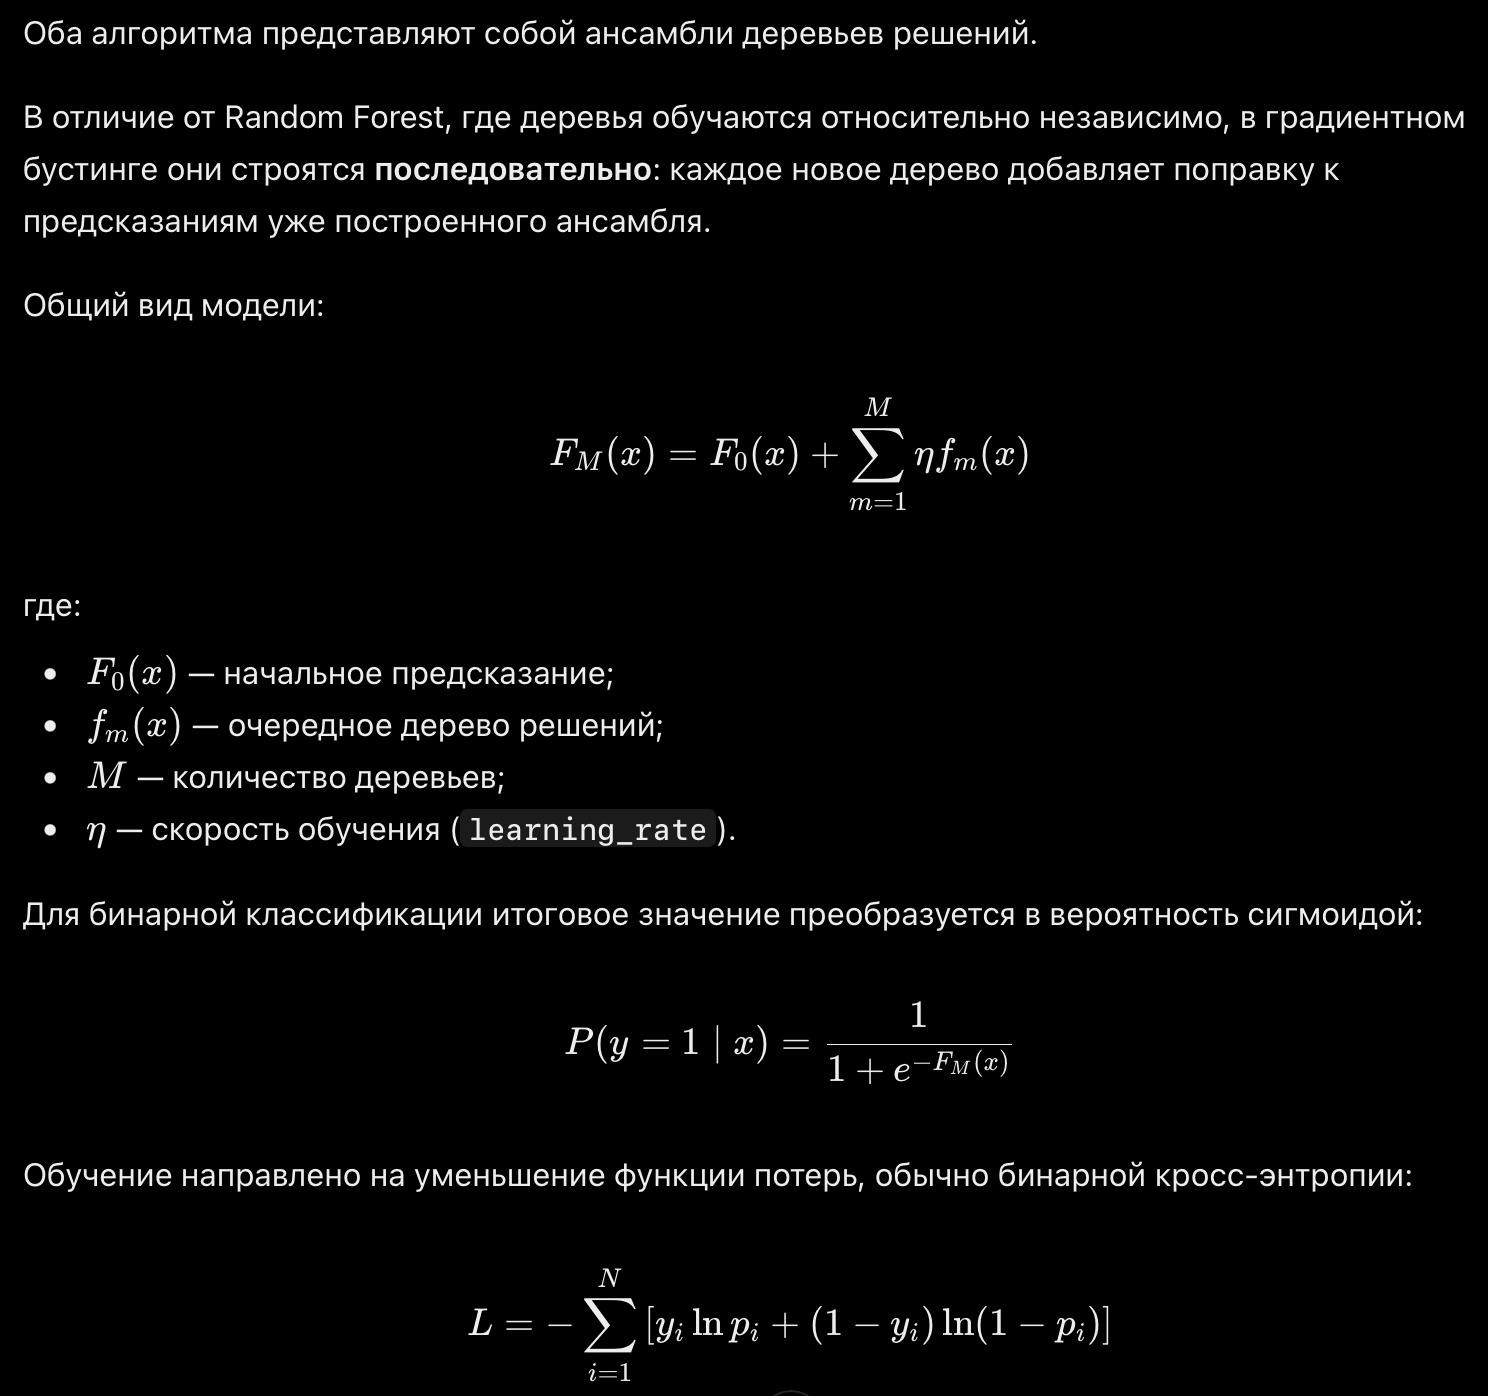 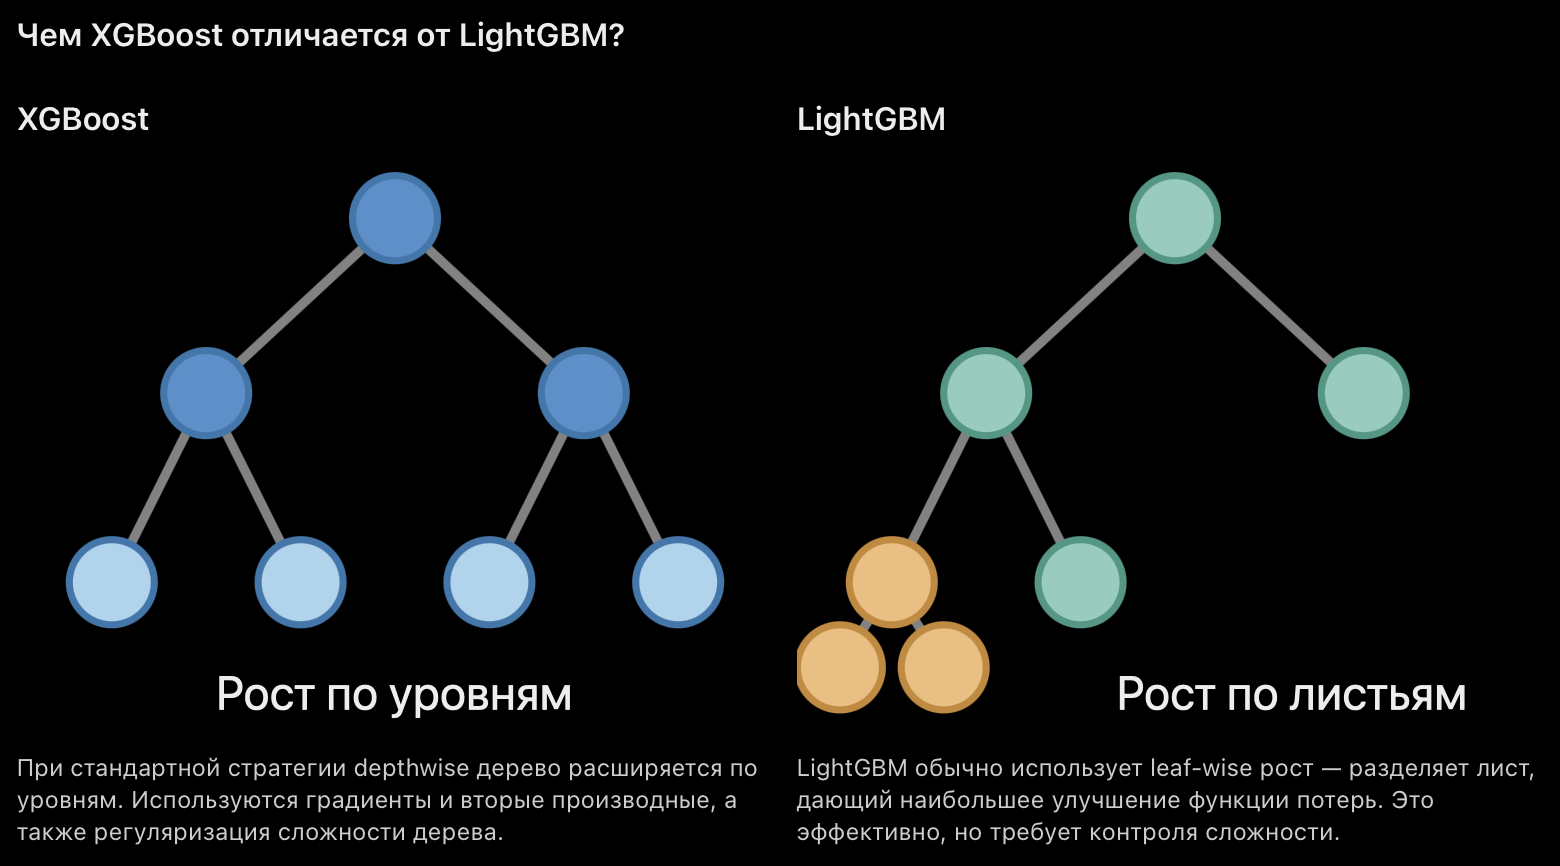

In [16]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_best = xgb_grid.best_estimator_
lgbm_best = lgbm_grid.best_estimator_

# Вероятности принадлежности к классу spam (1)
xgb_proba = xgb_best.predict_proba(X_test)[:, 1]
lgbm_proba = lgbm_best.booster_.predict(X_test)

probabilities = {
    "XGBoost": xgb_proba,
    "LightGBM": lgbm_proba
}

results = []

for name, y_proba in probabilities.items():
    y_pred = (y_proba >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

metrics_df = pd.DataFrame(results).set_index("Model")

print(metrics_df.round(4))

          Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                   
XGBoost     0.9848     0.9853  0.8993    0.9404   0.9876
LightGBM    0.9857     0.9650  0.9262    0.9452   0.9869


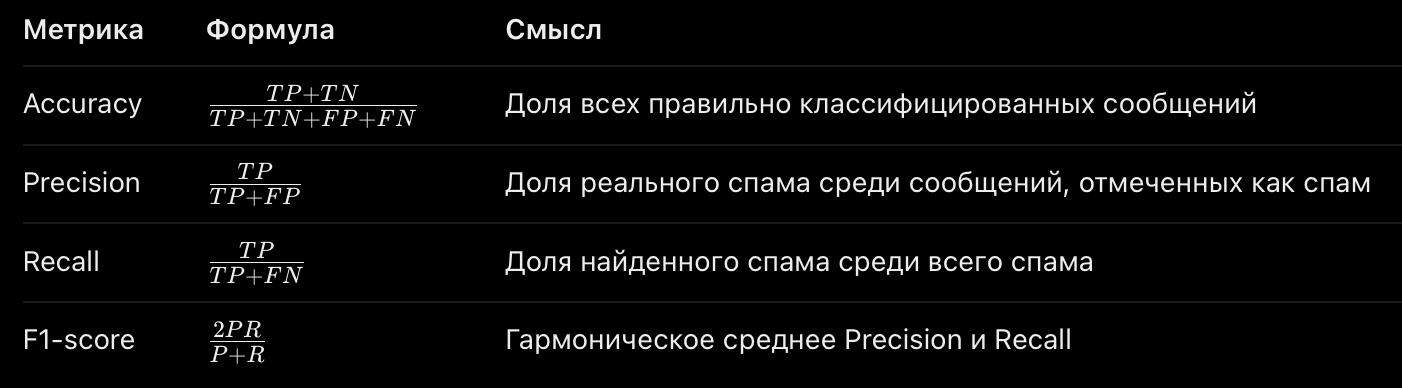

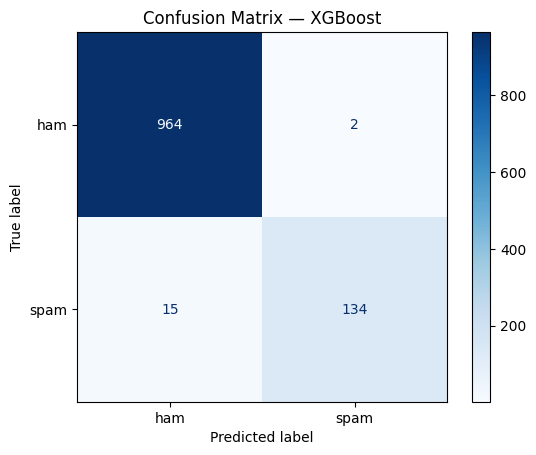

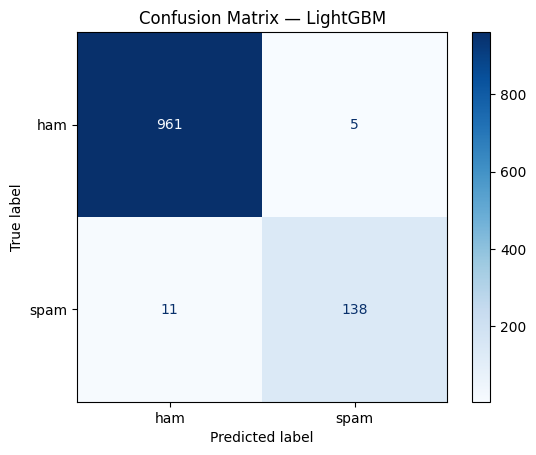

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, y_proba in probabilities.items():
    y_pred = (y_proba >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["ham", "spam"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix — {name}")
    plt.show()

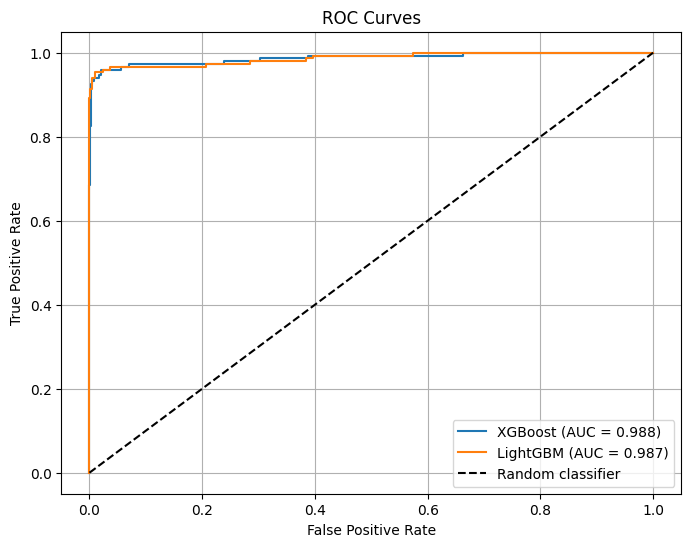

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for name, y_proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid()
plt.show()

# Задание 3.
Датасет: `datasets/crime_and_punishment.txt`. Необходимо построить вероятностную модель языка по тексту. Для этого используйте двух-граммную, трех-граммную и четырех-граммную модель. Сгенерируйте текст из 100 слов с помощью получившихся моделей.

In [21]:
with open("crime_and_punishment.txt", "r", encoding="utf-8") as f:
    text = f.read()

tokens = re.findall(r"[а-яёa-z]+", text.lower())

print("Words count:", len(tokens))
print("First 30 words:", tokens[:30])

Words count: 173358
First 30 words: ['федор', 'михайлович', 'достоевский', 'преступление', 'и', 'наказание', 'роман', 'в', 'шести', 'частях', 'с', 'эпилогом', 'часть', 'первая', 'i', 'в', 'начале', 'июля', 'в', 'чрезвычайно', 'жаркое', 'время', 'под', 'вечер', 'один', 'молодой', 'человек', 'вышел', 'из', 'своей']


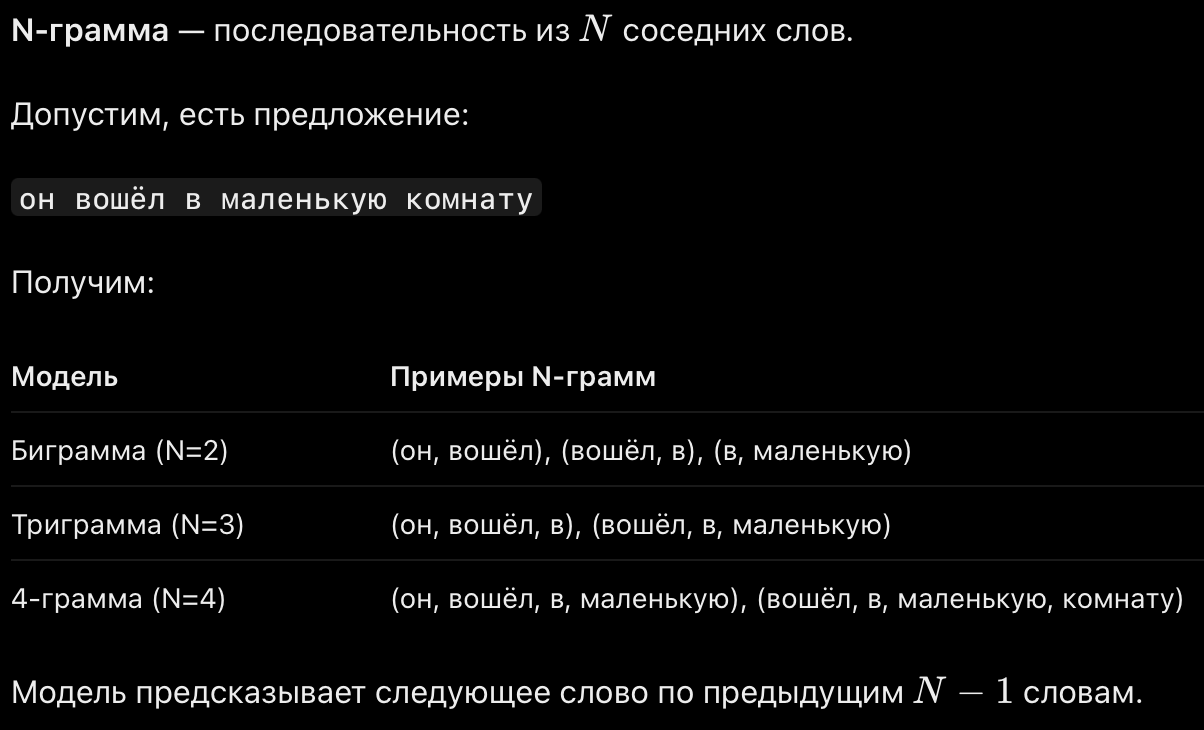 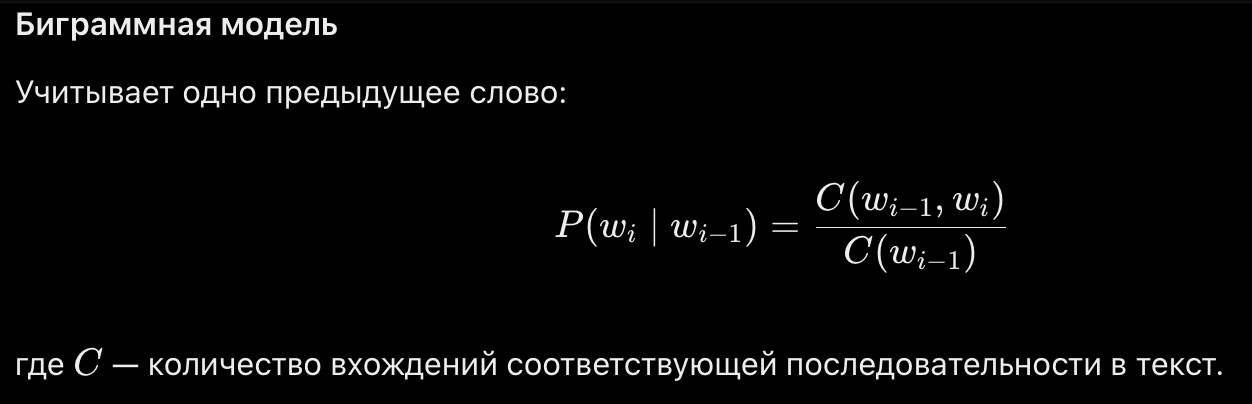 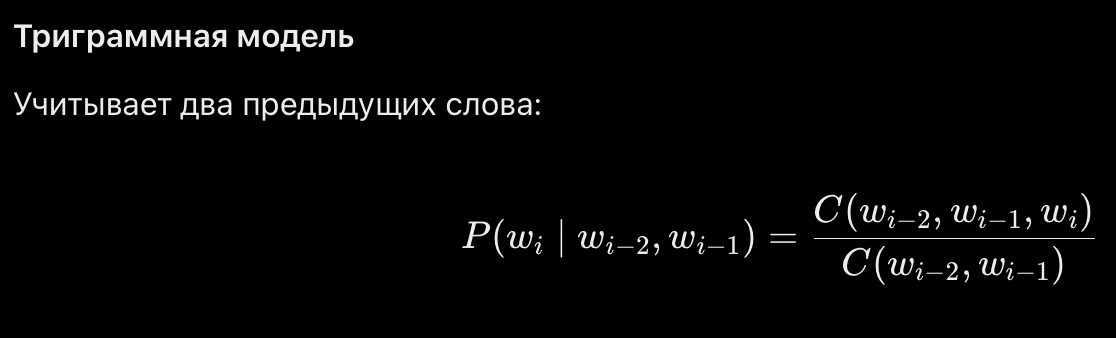 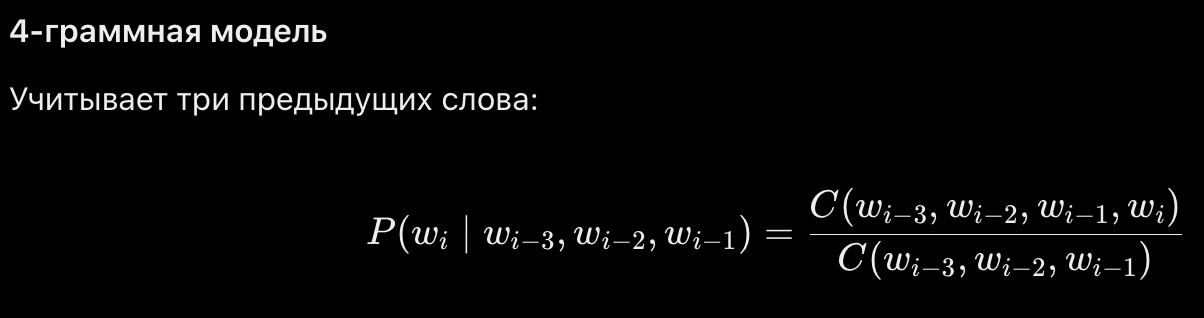

In [23]:
from collections import defaultdict, Counter

def build_ngram_model(tokens, n):
    model = defaultdict(Counter)

    for i in range(len(tokens) - n + 1):
        context = tuple(tokens[i:i+n-1])
        next_word = tokens[i+n-1]

        model[context][next_word] += 1

    return dict(model)

# returns smth like that (n =1)
#{
#    ("он",): Counter({
#        "сказал": 50,
#        "подумал": 20
#    }),
#    ("в",): Counter({
#        "комнату": 15,
#        "доме": 10
#    })
#}

In [26]:
bigram_model = build_ngram_model(tokens, 2)
trigram_model = build_ngram_model(tokens, 3)
fourgram_model = build_ngram_model(tokens, 4)

print("Unique bigram contexts count:", len(bigram_model))
print("Unique 3-gram contexts count:", len(trigram_model))
print("Unique 4-gram contexts count:", len(fourgram_model))

Unique bigram contexts count: 24929
Unique 3-gram contexts count: 111110
Unique 4-gram contexts count: 161286


In [25]:
context = ("он",)

counts = bigram_model.get(context, Counter())
total = sum(counts.values())

for word, count in counts.most_common(10):
    print(word, round(count / total, 4))

не 0.0361
вдруг 0.0298
и 0.027
был 0.0231
с 0.0193
уже 0.0154
в 0.014
как 0.0126
к 0.0119
на 0.0112


In [28]:
import random

def generate_text(model, n, num_words=100):
    context = random.choice(list(model.keys()))
    generated = list(context)

    while len(generated) < num_words:
        counts = model.get(context)

        if not counts:
            context = random.choice(list(model.keys()))   #равновероятный выбор начального случайного контекста
            generated.extend(context[:num_words - len(generated)])
            continue

        next_word = random.choices(
            population=list(counts.keys()),
            weights=list(counts.values()),
            k=1
        )[0]                                               #выбирает одно следующее слово с вероятностью, пропорциональной его наблюдаемой частоте

        generated.append(next_word)

        context = tuple(generated[-(n-1):])

    return " ".join(generated)

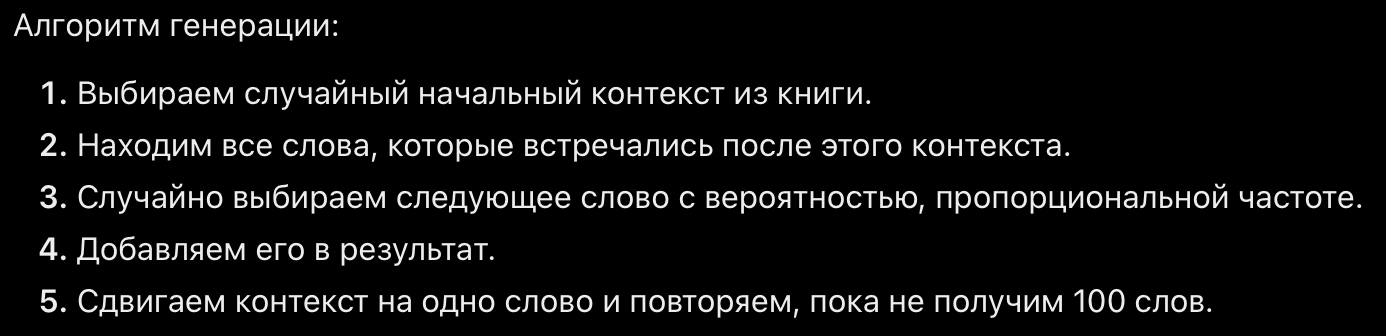

In [29]:
random.seed(666)

print("=== BIGRAM MODEL ===\n")
bigram_text = generate_text(bigram_model, 2, 100)
print(bigram_text)

print("\n=== TRIGRAM MODEL ===\n")
trigram_text = generate_text(trigram_model, 3, 100)
print(trigram_text)

print("\n=== 4-GRAM MODEL ===\n")
fourgram_text = generate_text(fourgram_model, 4, 100)
print(fourgram_text)

=== BIGRAM MODEL ===

оказываемым вам в десять длиной имевшая какой то раз припоминал прежнее безмолвное прямое сиденье на щеках тоже вероятно приняв раскольникова что она совсем человек первый разговор о том месте где политическая экономия зачем рога о них товары и почти голубая вода не заметила она не хотят что возможности и стала ожидать порфирий петрович перевел дыхание но мышь подумал сунул мигом весь предыдущий разговор и он куда тебя так случился ну если бы он придерживал правою рукой и довольно неосторожного вызова а впрочем полною и забыл он угрюмо задумался о фирме разумеется их и теснились только самим собою турку на которую

=== TRIGRAM MODEL ===

вставать ему сделалось и тяжело и больно больно сжало вдруг ей сердце с ней до крайности небрежно что та минута пришла опять он потащил его к губам но опомнившись с отвращением подумал раскольников ну тка софья семеновна перед многоуважаемой вашей сестрице что в ихней статье все люди как мы выходили брякнул разумихин только что по